<a href="https://colab.research.google.com/github/Shivankar7/Shivankar-Sinha/blob/main/Shivankar_sinha_23BDS0026_EDA_Fertility_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
plt.style.use("ggplot")
print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# Load Dataset

from google.colab import files
uploaded = files.upload()
df = pd.read_csv("Fertility2.csv")

Saving Fertility2.csv to Fertility2.csv


In [3]:
#Display Dataset
print("First Five Rows")
display(df.head())
print("\nLast Five Rows")
display(df.tail())

First Five Rows


,rownames,morekids,gender1,gender2,age,afam,hispanic,other,work
0,1,no,female,female,35,no,no,no,40
1,2,no,female,male,33,no,no,no,52
2,3,no,female,female,28,no,no,no,12
3,4,no,male,male,28,no,no,no,0
4,5,no,female,male,31,no,no,no,0



Last Five Rows


,rownames,morekids,gender1,gender2,age,afam,hispanic,other,work
29995,29996,yes,male,female,34,no,no,no,0
29996,29997,no,male,male,30,no,no,no,4
29997,29998,yes,male,female,34,no,no,no,42
29998,29999,yes,male,male,31,yes,no,no,52
29999,30000,no,female,female,29,no,no,no,0


In [4]:
#Dataset Information
print("Shape of Dataset:", df.shape)
print("\nColumn Names")
print(df.columns)
print("\nData Types")
print(df.dtypes)
print("\nInformation")
df.info()

Shape of Dataset: (30000, 9)

Column Names
Index(['rownames', 'morekids', 'gender1', 'gender2', 'age', 'afam', 'hispanic',
       'other', 'work'],
      dtype='object')

Data Types
rownames     int64
morekids    object
gender1     object
gender2     object
age          int64
afam        object
hispanic    object
other       object
work         int64
dtype: object

Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   rownames  30000 non-null  int64 
 1   morekids  30000 non-null  object
 2   gender1   30000 non-null  object
 3   gender2   30000 non-null  object
 4   age       30000 non-null  int64 
 5   afam      30000 non-null  object
 6   hispanic  30000 non-null  object
 7   other     30000 non-null  object
 8   work      30000 non-null  int64 
dtypes: int64(3), object(6)
memory usage: 2.1+ MB


In [5]:
#Statistical Analysis
print("Statistical Summary")
display(df.describe())

Statistical Summary


,rownames,age,work
count,30000.000000,30000.000000,30000.000000
mean,15000.500000,30.354267,19.209500
std,8660.398374,3.383432,21.941018
min,1.000000,21.000000,0.000000
25%,7500.750000,28.000000,0.000000
50%,15000.500000,31.000000,6.000000
75%,22500.250000,33.000000,45.000000
max,30000.000000,35.000000,52.000000


rownames    0
morekids    0
gender1     0
gender2     0
age         0
afam        0
hispanic    0
other       0
work        0
dtype: int64
rownames    0.0
morekids    0.0
gender1     0.0
gender2     0.0
age         0.0
afam        0.0
hispanic    0.0
other       0.0
work        0.0
dtype: float64


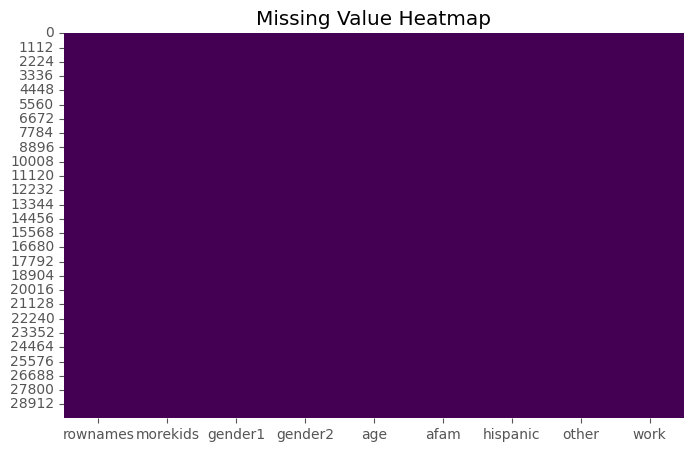

In [6]:
#Missing data analysis
print(df.isnull().sum())
missing = (df.isnull().sum()/len(df))*100
print(missing)
plt.figure(figsize=(8,5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Value Heatmap")
plt.show()

In [7]:
#Handle Missing Values
numeric_columns=df.select_dtypes(include=np.number).columns

df[numeric_columns]=df[numeric_columns].fillna(df[numeric_columns].mean())
categorical_columns=df.select_dtypes(include='object').columns

for col in categorical_columns:
    df[col]=df[col].fillna(df[col].mode()[0])

In [8]:
#Data cleaning
print("Duplicate Rows =",df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Duplicates Removed")
df.columns=df.columns.str.strip()
df.columns

Duplicate Rows = 0
Duplicates Removed


Index(['rownames', 'morekids', 'gender1', 'gender2', 'age', 'afam', 'hispanic',
       'other', 'work'],
      dtype='object')

In [9]:
#Data transformation

#1.Label Encoding
encoder=LabelEncoder()

for col in categorical_columns:
    df[col]=encoder.fit_transform(df[col])

print("Categorical Data Encoded Successfully")

#2.Feature Scaling
scaler=StandardScaler()

df[numeric_columns]=scaler.fit_transform(df[numeric_columns])

print("Numerical Features Standardized")

Categorical Data Encoded Successfully
Numerical Features Standardized


Histogram


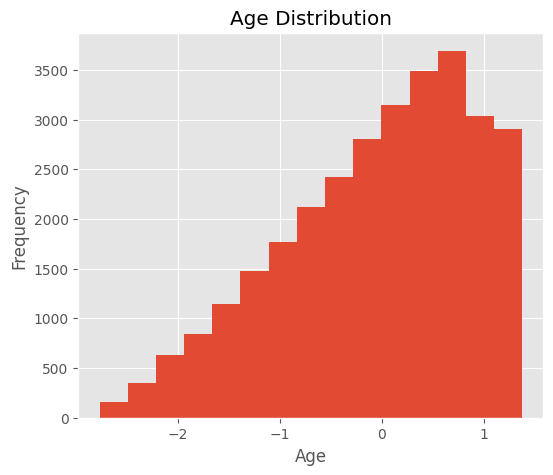

Boxplot


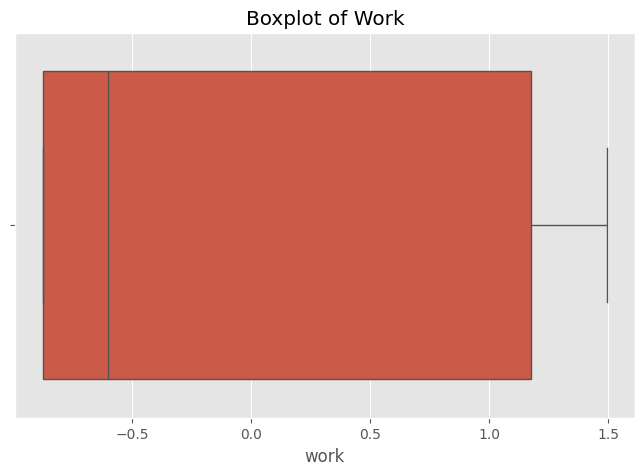

Count Plot


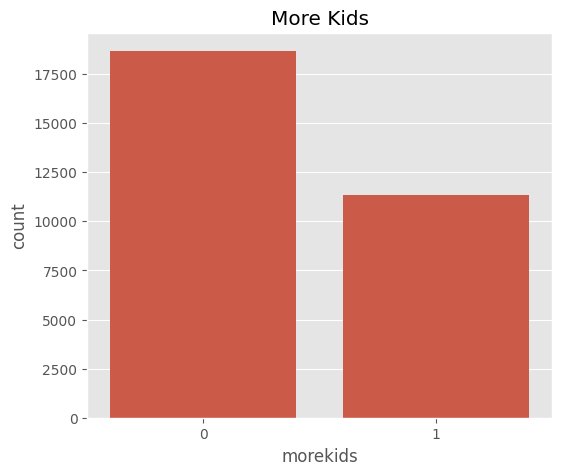

In [10]:
#Univariate analysis with a minimum of three visualizations

#1.Histogram (Age)
print("Histogram")
plt.figure(figsize=(6,5))
plt.hist(df["age"],bins=15)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

#2.Boxplot
print("Boxplot")
plt.figure(figsize=(8,5))
sns.boxplot(x=df["work"])
plt.title("Boxplot of Work")
plt.show()

#3.Count Plot
print("Count Plot")
plt.figure(figsize=(6,5))
sns.countplot(x="morekids",data=df)
plt.title("More Kids")
plt.show()

Scatter Plot


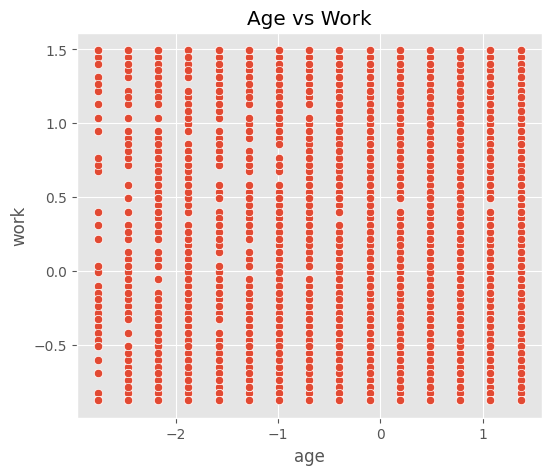

Boxplot


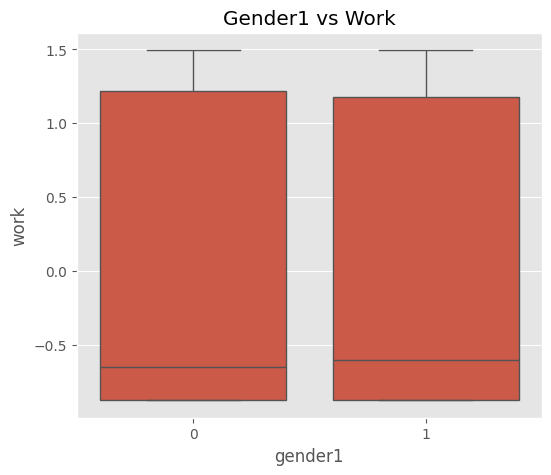

Heatmap


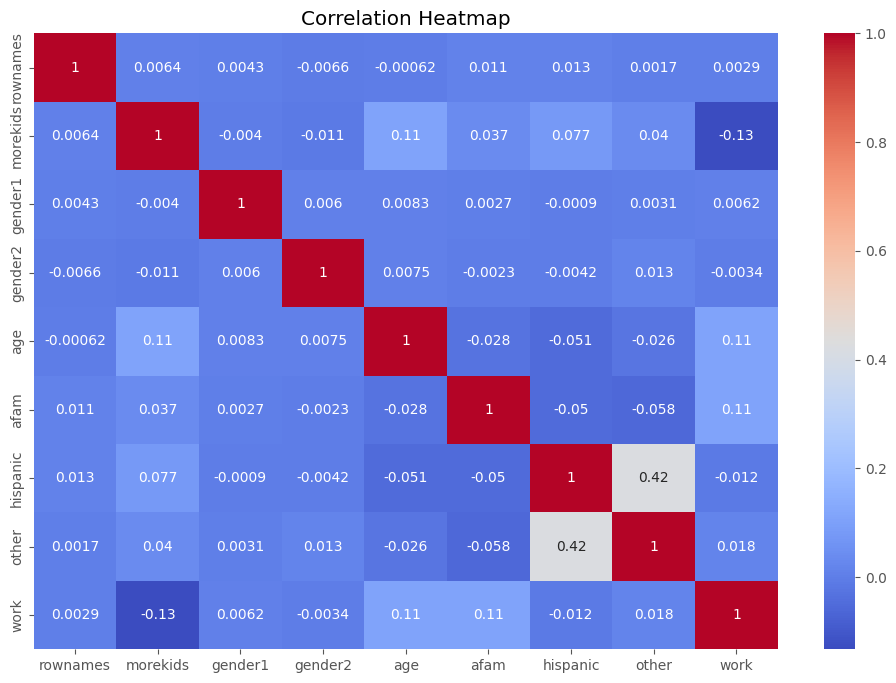

In [11]:
#Bivariate analysis with a minimum of three visualizations

#1.Scatter Plot(Age vs Work)
print("Scatter Plot")
plt.figure(figsize=(6,5))
sns.scatterplot(x="age",y="work",data=df)
plt.title("Age vs Work")
plt.show()

#2.Boxplot(Gender1 vs Work)
print("Boxplot")
plt.figure(figsize=(6,5))
sns.boxplot(x="gender1",y="work",data=df)
plt.title("Gender1 vs Work")
plt.show()

#3.Correlation Heatmap
print("Heatmap")
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

Pair plot


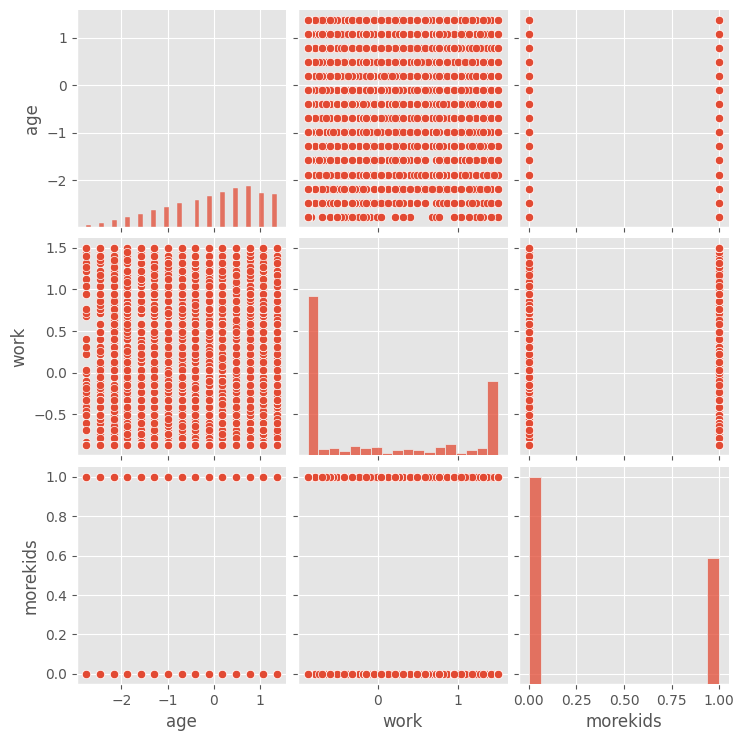

Heatmap


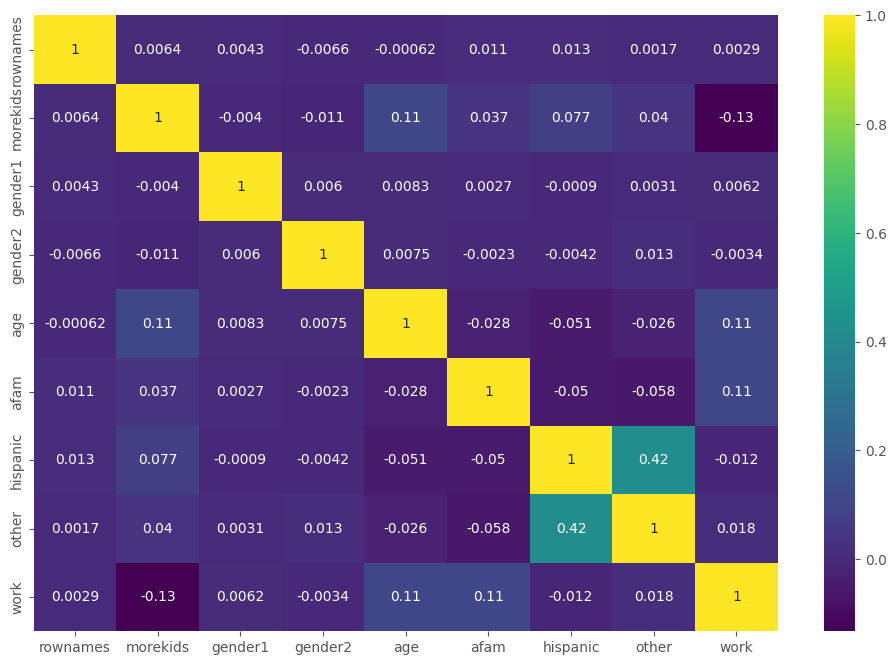

Scatter Plot


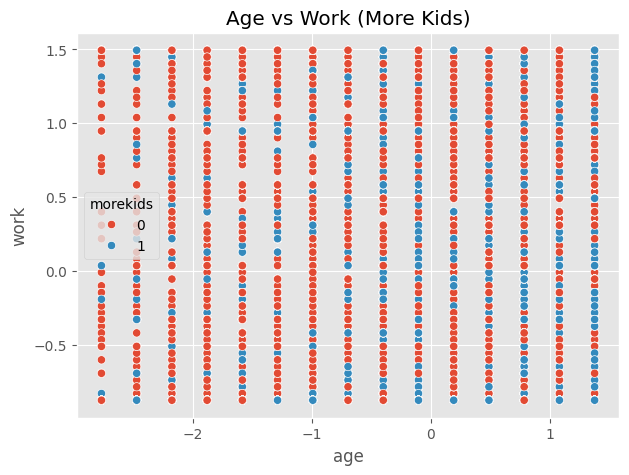

In [12]:
#Multivariate analysis with a minimum of three visualizations

#1.Pair Plot
print("Pair plot")
sns.pairplot(df[["age","work","morekids"]])
plt.show()

#2.Heatmap
print("Heatmap")
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot=True,cmap="viridis")
plt.show()

#3.Scatter Plot
print("Scatter Plot")
plt.figure(figsize=(7,5))
sns.scatterplot(x="age",y="work",hue="morekids",data=df)
plt.title("Age vs Work (More Kids)")
plt.show()

In [13]:
#Final Dataset
df.head()

,rownames,morekids,gender1,gender2,age,afam,hispanic,other,work
0,-1.731993,0,0,0,1.373106,0,0,0,0.947579
1,-1.731878,0,0,1,0.781980,0,0,0,1.494509
2,-1.731762,0,0,0,-0.695834,0,0,0,-0.328591
3,-1.731647,0,1,1,-0.695834,0,0,0,-0.875521
4,-1.731531,0,0,1,0.190855,0,0,0,-0.875521


In [14]:
# Basic libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Machine Learning / Clustering
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Hierarchical clustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Display settings
pd.set_option('display.max_columns', None)

sns.set_style("whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


1-D ANALYSIS


In [15]:
#1-D Analysis
print("AGE")
print("Mean:", df['age'].mean())
print("Median:", df['age'].median())
print("Mode:", df['age'].mode()[0])
print("\nWORK")
print("Mean:", df['work'].mean())
print("Median:", df['work'].median())
print("Mode:", df['work'].mode()[0])

AGE
Mean: -2.6586140696357083e-16
Median: 0.190854775159232
Mode: 0.7819804467240646

WORK
Mean: 4.784321087451341e-17
Median: -0.6020559464673004
Mode: -0.8755209283972603


In [16]:
print("Age Quartiles:")
print(df['age'].quantile([0.25, 0.50, 0.75]))

print("\nAge IQR:")
print(df['age'].quantile(0.75) - df['age'].quantile(0.25))
print("Work Quartiles:")
print(df['work'].quantile([0.25, 0.50, 0.75]))

print("\nWork IQR:")
print(df['work'].quantile(0.75) - df['work'].quantile(0.25))

Age Quartiles:
0.25   -0.695834
0.50    0.190855
0.75    0.781980
Name: age, dtype: float64

Age IQR:
1.4778141789120816
Work Quartiles:
0.25   -0.875521
0.50   -0.602056
0.75    1.175466
Name: work, dtype: float64

Work IQR:
2.050987364474698


In [17]:
print("Age Skewness:", df['age'].skew())
print("Age Kurtosis:", df['age'].kurtosis())

print("\nWork Skewness:", df['work'].skew())
print("Work Kurtosis:", df['work'].kurtosis())

Age Skewness: -0.5802137057893045
Age Kurtosis: -0.45708451164859776

Work Skewness: 0.5227518044153043
Work Kurtosis: -1.4926441556082226


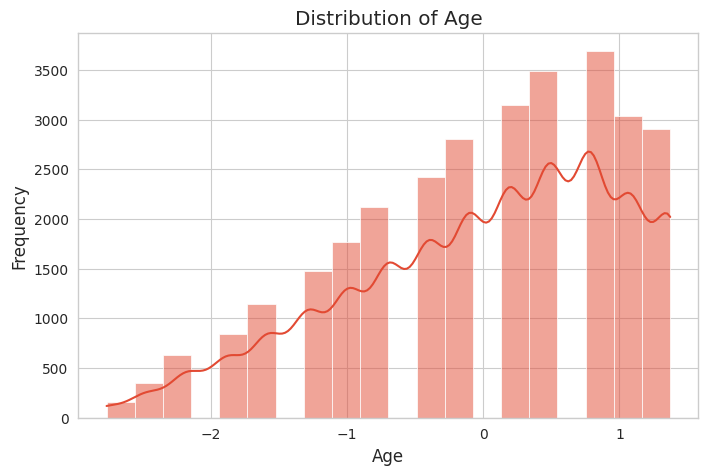

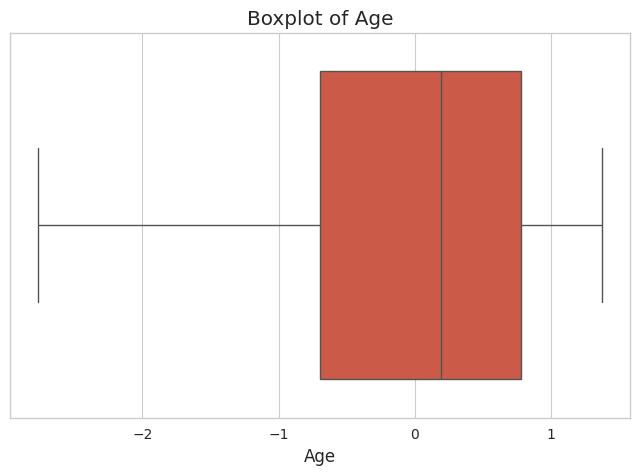

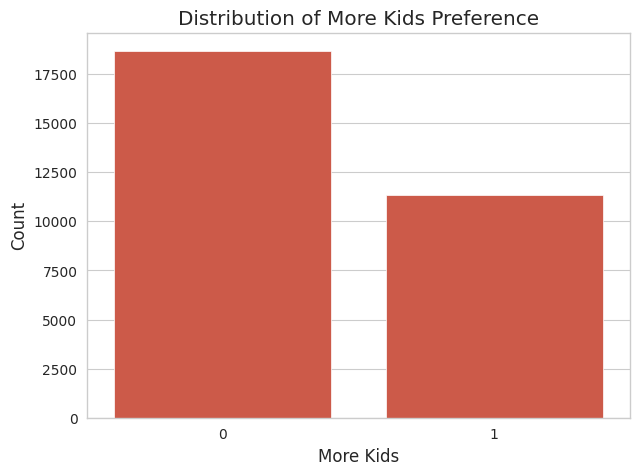

In [18]:
#Histogram
plt.figure(figsize=(8,5))

sns.histplot(df['age'], bins=20, kde=True)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

#Boxplot
plt.figure(figsize=(8,5))

sns.boxplot(x=df['age'])

plt.title("Boxplot of Age")
plt.xlabel("Age")

plt.show()

#Bar chart
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='morekids')

plt.title("Distribution of More Kids Preference")
plt.xlabel("More Kids")
plt.ylabel("Count")

plt.show()


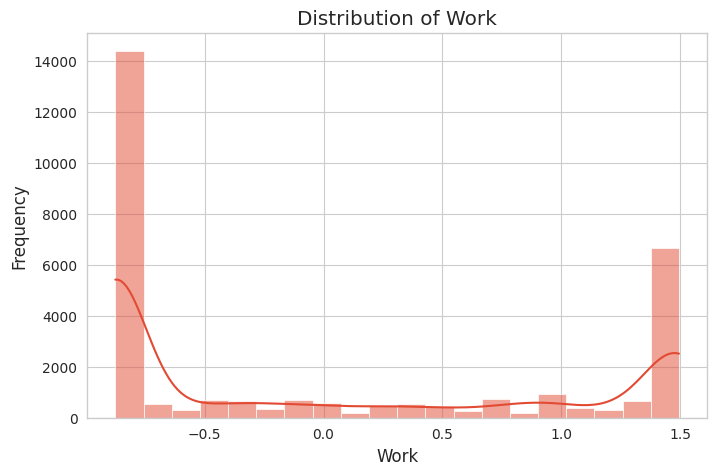

In [19]:
plt.figure(figsize=(8,5))

sns.histplot(df['work'], bins=20, kde=True)

plt.title("Distribution of Work")
plt.xlabel("Work")
plt.ylabel("Frequency")

plt.show()

2-D ANALYSIS


In [20]:
correlation = df[['age', 'work']].corr()

print(correlation)

           age      work
age   1.000000  0.109168
work  0.109168  1.000000


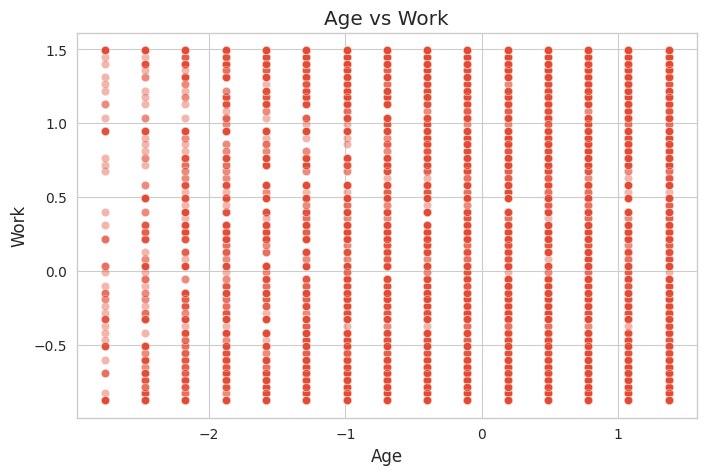

In [21]:
#Scatter plot
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x='age', y='work', alpha=0.4)

plt.title("Age vs Work")
plt.xlabel("Age")
plt.ylabel("Work")

plt.show()

In [23]:
covariance = df[['age', 'work']].cov()

print(covariance)


           age      work
age   1.000033  0.109172
work  0.109172  1.000033


In [24]:
correlation_value, p_value = stats.pearsonr(
    df['age'],
    df['work']
)

print("Correlation:", correlation_value)
print("P-value:", p_value)

Correlation: 0.10916794732392648
P-value: 3.3612072694039302e-80


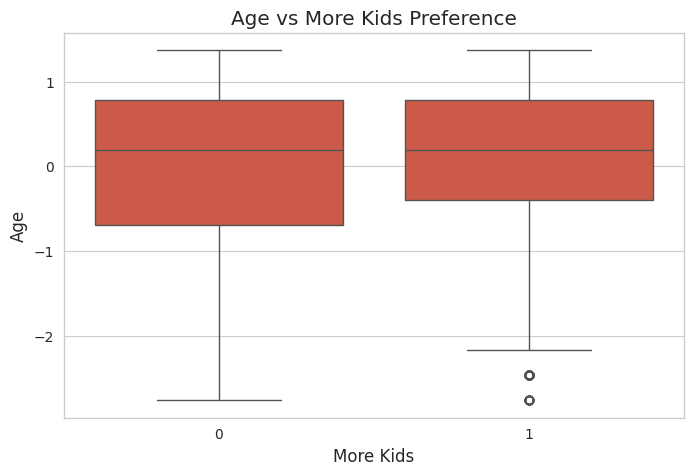

In [25]:
#numerical vs categorical
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='morekids', y='age')

plt.title("Age vs More Kids Preference")
plt.xlabel("More Kids")
plt.ylabel("Age")

plt.show()

In [26]:
print(
    df.groupby('morekids')['age']
      .agg(['mean', 'median', 'std', 'min', 'max'])
)

              mean    median       std       min       max
morekids                                                  
0        -0.084557  0.190855  1.017944 -2.764774  1.373106
1         0.139377  0.190855  0.953560 -2.764774  1.373106


In [27]:
yes_age = df[df['morekids'] == 'yes']['age']
no_age = df[df['morekids'] == 'no']['age']

t_stat, p_value = stats.ttest_ind(
    yes_age,
    no_age,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: nan
P-value: nan


/usr/local/lib/python3.13/dist-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)


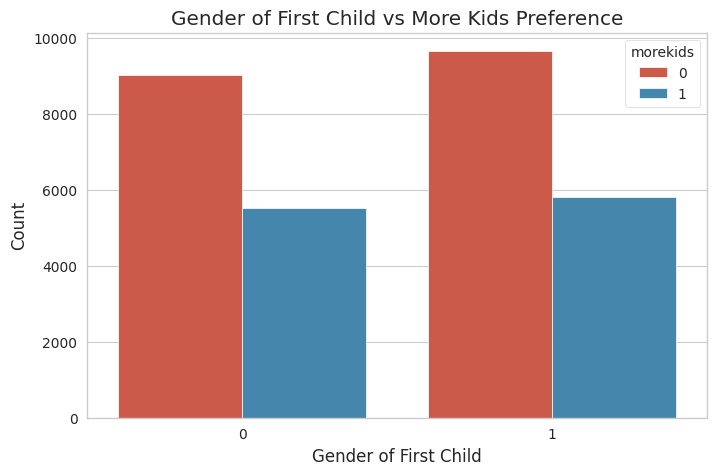

In [28]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='gender1',
    hue='morekids'
)

plt.title("Gender of First Child vs More Kids Preference")
plt.xlabel("Gender of First Child")
plt.ylabel("Count")

plt.show()

In [29]:
gender_morekids = pd.crosstab(
    df['gender1'],
    df['morekids']
)

print(gender_morekids)

morekids     0     1
gender1             
0         9026  5523
1         9646  5805


In [30]:
chi2, p, dof, expected = stats.chi2_contingency(
    gender_morekids
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p)

Chi-square statistic: 0.47091501583342765
Degrees of freedom: 1
P-value: 0.49256651941583895


N-D ANALYSIS


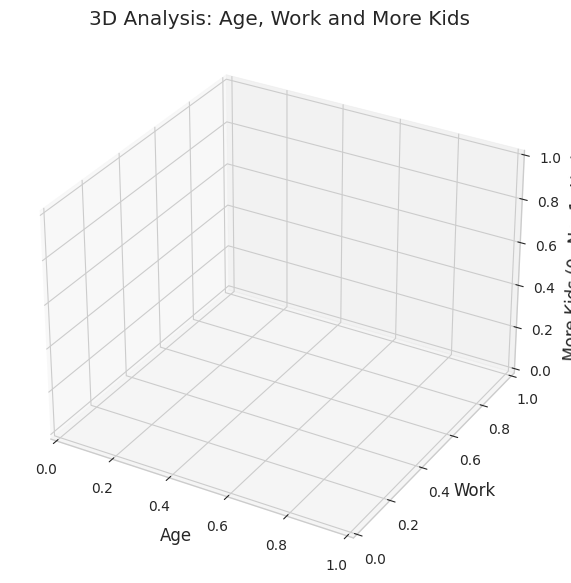

In [32]:
from mpl_toolkits.mplot3d import Axes3D

# Encode morekids for 3D visualization
df_3d = df.copy()

df_3d['morekids_num'] = df_3d['morekids'].map({
    'no': 0,
    'yes': 1
})

fig = plt.figure(figsize=(10,7))

ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    df_3d['age'],
    df_3d['work'],
    df_3d['morekids_num'],
    alpha=0.4
)

ax.set_xlabel('Age')
ax.set_ylabel('Work')
ax.set_zlabel('More Kids (0=No, 1=Yes)')

ax.set_title('3D Analysis: Age, Work and More Kids')

plt.show()

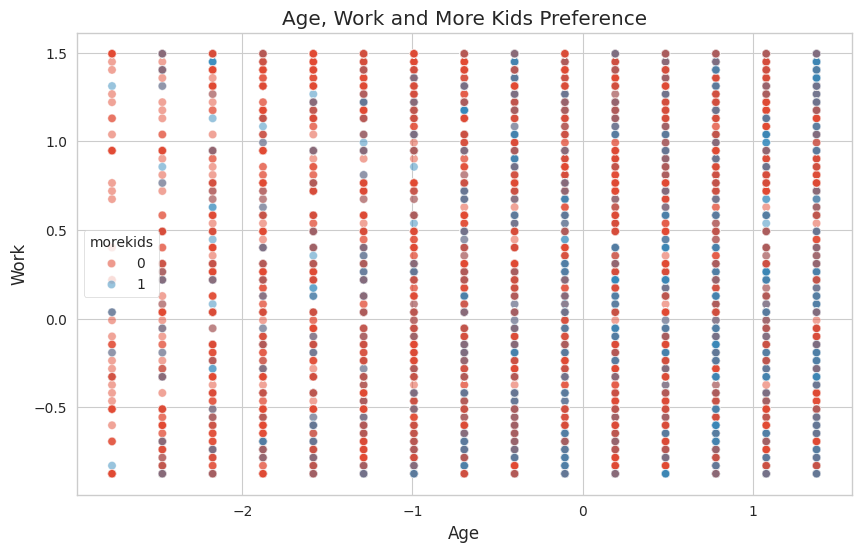

In [33]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='age',
    y='work',
    hue='morekids',
    alpha=0.5
)

plt.title("Age, Work and More Kids Preference")
plt.xlabel("Age")
plt.ylabel("Work")

plt.show()

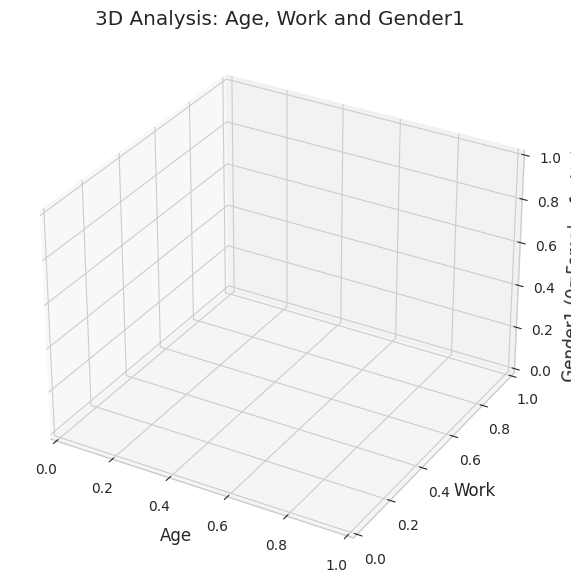

In [34]:
df_3d['gender1_num'] = df_3d['gender1'].map({
    'female': 0,
    'male': 1
})

fig = plt.figure(figsize=(10,7))

ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    df_3d['age'],
    df_3d['work'],
    df_3d['gender1_num'],
    alpha=0.4
)

ax.set_xlabel('Age')
ax.set_ylabel('Work')
ax.set_zlabel('Gender1 (0=Female, 1=Male)')

ax.set_title('3D Analysis: Age, Work and Gender1')

plt.show()

K-MEANS CLUSTERING

In [37]:
num_df = df.select_dtypes(include=np.number)

print("Numerical columns:")
print(num_df.columns.tolist())

Numerical columns:
['rownames', 'morekids', 'gender1', 'gender2', 'age', 'afam', 'hispanic', 'other', 'work']


In [38]:
X = num_df.copy()

X = X.fillna(X.median())

print("Missing values:")
print(X.isnull().sum())
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized data:")
print(X_scaled[:5])

Missing values:
rownames    0
morekids    0
gender1     0
gender2     0
age         0
afam        0
hispanic    0
other       0
work        0
dtype: int64
Standardized data:
[[-1.73199307 -0.7788991  -1.03053258 -1.01220784  1.37310612 -0.23719959
  -0.28351419 -0.24547504  0.94757895]
 [-1.7318776  -0.7788991  -1.03053258  0.98793939  0.78198045 -0.23719959
  -0.28351419 -0.24547504  1.49450891]
 [-1.73176213 -0.7788991  -1.03053258 -1.01220784 -0.69583373 -0.23719959
  -0.28351419 -0.24547504 -0.32859096]
 [-1.73164666 -0.7788991   0.97037204  0.98793939 -0.69583373 -0.23719959
  -0.28351419 -0.24547504 -0.87552093]
 [-1.73153119 -0.7788991  -1.03053258  0.98793939  0.19085478 -0.23719959
  -0.28351419 -0.24547504 -0.87552093]]


In [44]:
K = 3
np.random.seed(42)

random_indices = np.random.choice(
    len(X_scaled),
    K,
    replace=False
)

centroids = X_scaled[random_indices]

print("Initial Centroids:")
print(centroids)

Initial Centroids:
[[-1.46548819 -0.7788991   0.97037204  0.98793939 -1.2869594  -0.23719959
  -0.28351419 -0.24547504 -0.87552093]
 [ 0.85499801 -0.7788991   0.97037204  0.98793939 -0.99139657 -0.23719959
  -0.28351419 -0.24547504 -0.87552093]
 [ 0.96965978 -0.7788991   0.97037204  0.98793939  0.48641761 -0.23719959
  -0.28351419  4.0737339  -0.55647845]]


In [45]:
np.random.seed(42)

random_indices = np.random.choice(
    len(X_scaled),
    K,
    replace=False
)

centroids = X_scaled[random_indices]

print("Initial Centroids:")
print(centroids)
def calculate_distance(point, centroid):
    return np.sqrt(np.sum((point - centroid) ** 2))

Initial Centroids:
[[-1.46548819 -0.7788991   0.97037204  0.98793939 -1.2869594  -0.23719959
  -0.28351419 -0.24547504 -0.87552093]
 [ 0.85499801 -0.7788991   0.97037204  0.98793939 -0.99139657 -0.23719959
  -0.28351419 -0.24547504 -0.87552093]
 [ 0.96965978 -0.7788991   0.97037204  0.98793939  0.48641761 -0.23719959
  -0.28351419  4.0737339  -0.55647845]]


In [46]:
def assign_clusters(X, centroids):

    labels = []

    for point in X:

        distances = []

        for centroid in centroids:

            distance = calculate_distance(
                point,
                centroid
            )

            distances.append(distance)

        labels.append(np.argmin(distances))

    return np.array(labels)

In [47]:
def update_centroids(X, labels, K):

    new_centroids = []

    for i in range(K):

        cluster_points = X[labels == i]

        if len(cluster_points) > 0:
            centroid = cluster_points.mean(axis=0)
        else:
            centroid = X[np.random.randint(len(X))]

        new_centroids.append(centroid)

    return np.array(new_centroids)

In [48]:
for iteration in range(100):

    # Assign points to clusters
    labels = assign_clusters(
        X_scaled,
        centroids
    )

    # Calculate new centroids
    new_centroids = update_centroids(
        X_scaled,
        labels,
        K
    )

    # Check convergence
    if np.allclose(centroids, new_centroids):
        print("Converged at iteration:", iteration + 1)
        break

    centroids = new_centroids

print("\nFinal Centroids:")
print(centroids)

print("\nCluster Labels:")
print(labels)

Converged at iteration: 18

Final Centroids:
[[-8.64302614e-01 -1.29425808e-02 -1.43863421e-02  1.34470799e-02
  -1.58346383e-04 -3.45589900e-02 -1.18183903e-01 -2.45475042e-01
  -3.77799963e-02]
 [ 8.64009381e-01 -6.47529177e-03  1.28579048e-02 -1.99832099e-02
   1.28441526e-02  6.31764209e-02 -8.84404133e-02 -2.45475042e-01
   2.91164941e-02]
 [ 6.99467471e-03  1.61139856e-01  1.27543489e-02  5.41463123e-02
  -1.05228113e-01 -2.37199586e-01  1.71457558e+00  4.07373390e+00
   7.20633022e-02]]

Cluster Labels:
[0 0 0 ... 1 1 1]


In [49]:
df["KMeans_Cluster"] = labels

print(df.head())
print(
    df["KMeans_Cluster"].value_counts().sort_index()
)

   rownames  morekids  gender1  gender2       age  afam  hispanic  other  \
0 -1.731993         0        0        0  1.373106     0         0      0   
1 -1.731878         0        0        1  0.781980     0         0      0   
2 -1.731762         0        0        0 -0.695834     0         0      0   
3 -1.731647         0        1        1 -0.695834     0         0      0   
4 -1.731531         0        0        1  0.190855     0         0      0   

       work  KMeans_Cluster  
0  0.947579               0  
1  1.494509               0  
2 -0.328591               0  
3 -0.875521               0  
4 -0.875521               0  
KMeans_Cluster
0    14152
1    14143
2     1705
Name: count, dtype: int64


In [50]:
final_wcss = 0

for i in range(len(X_scaled)):

    final_wcss += np.sum(
        (X_scaled[i] - centroids[labels[i]]) ** 2
    )

print("Final WCSS:", final_wcss)

Final WCSS: 213252.06246995422


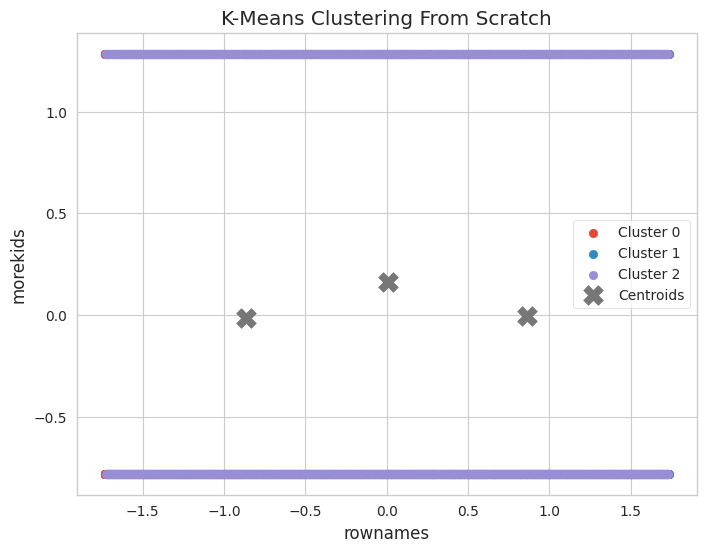

In [51]:
plt.figure(figsize=(8, 6))

for cluster in range(K):

    points = X_scaled[labels == cluster]

    plt.scatter(
        points[:, 0],
        points[:, 1],
        label=f"Cluster {cluster}"
    )

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel(num_df.columns[0])
plt.ylabel(num_df.columns[1])

plt.title("K-Means Clustering From Scratch")

plt.legend()
plt.show()

In [52]:
df.to_csv(
    "Fertility2_KMeans_Result.csv",
    index=False
)

print("K-Means results saved successfully.")

K-Means results saved successfully.


HIERARCHICAL CLUSTERING

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [55]:
from scipy.cluster.hierarchy import dendrogram, linkage

In [56]:
num_df = df.select_dtypes(include=np.number)

print("Numerical columns:")
print(num_df.columns.tolist())
def euclidean_distance(point1, point2):

    return np.sqrt(
        np.sum((point1 - point2) ** 2)
    )

Numerical columns:
['rownames', 'morekids', 'gender1', 'gender2', 'age', 'afam', 'hispanic', 'other', 'work', 'KMeans_Cluster']


In [57]:
clusters = []

for i in range(len(X_scaled)):

    clusters.append([i])

print("Number of initial clusters:", len(clusters))
def cluster_distance(cluster1, cluster2, X):

    minimum_distance = float("inf")

    for i in cluster1:

        for j in cluster2:

            distance = euclidean_distance(
                X[i],
                X[j]
            )

            if distance < minimum_distance:
                minimum_distance = distance

    return minimum_distance

Number of initial clusters: 30000


In [58]:
def find_closest_clusters(clusters, X):

    minimum_distance = float("inf")

    cluster_pair = None

    for i in range(len(clusters)):

        for j in range(i + 1, len(clusters)):

            distance = cluster_distance(
                clusters[i],
                clusters[j],
                X
            )

            if distance < minimum_distance:

                minimum_distance = distance

                cluster_pair = (i, j)

    return cluster_pair, minimum_distance

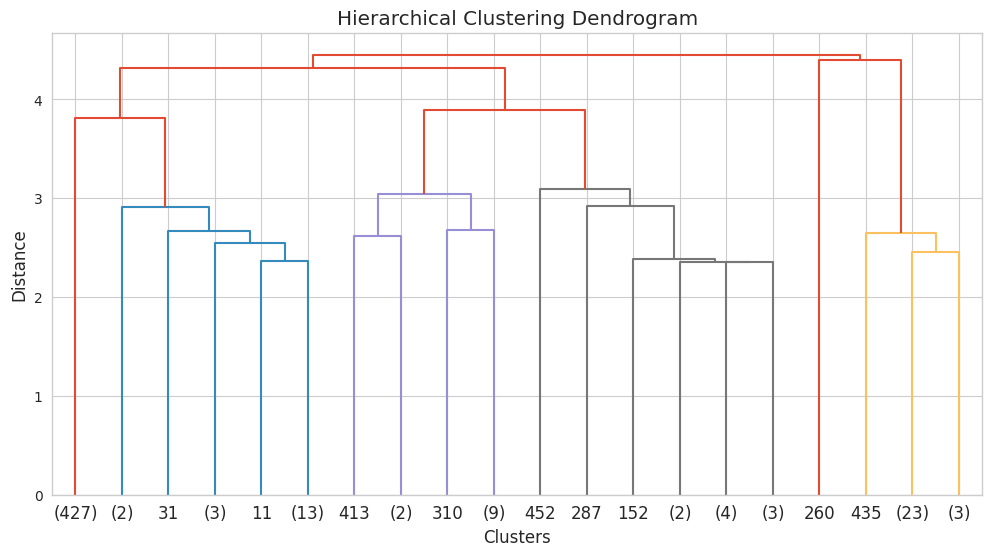

In [62]:
Z = linkage(
    X_sample,
    method='single'
)

plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=20
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")

plt.show()

In [67]:
for cluster_number in range(K):

    count = np.sum(
        labels == cluster_number
    )

    print(
        "Cluster",
        cluster_number,
        ":",
        count,
        "points"
    )

Cluster 0 : 14152 points
Cluster 1 : 14143 points
Cluster 2 : 1705 points


In [69]:
labels = np.zeros(len(X_sample), dtype=int)

for cluster_number, cluster in enumerate(clusters):

    for index in cluster:

        labels[index] = cluster_number

print("Cluster labels:")
print(labels)

Cluster labels:
[  0 435   1   2   3   4   5   6   7   8   9  10  11  12 417  13 411  14
  15  16  17  18 403 404  19  20 418 432  21  22 411  23 398  24  25  26
  27 414 398 428 399  28 400 409  29  30  31  32  33  34  35  36  37  38
 390  39  40  41  42 421  43  44  45  46 392  47 418  48  49  50  51  52
  53  54  55  56 425  57  58  59  60  61 410  62 403  63  64 433 431 432
  65  66 430 394 391  67  68  69  70  71  72  73 424  74  75  76  77 404
  78 424  79  80  81  82  83  84  85  86 417 408  87  88 409  89  90  91
  92  93 390 426 426  94  95  96  97 419  98  99 100 101 102 103 104 420
 105 106 107 108 109 407 110 111 112 113 114 115 116 117 118 434 119 120
 121 122 417 123 124 125 126 127 128 129 130 131 132 133 134 135 136 137
 138 139 140 141 142 143 144 393 145 146 147 395 148 149 150 151 152 153
 154 155 156 157 158 159 160 161 162 163 164 391 165 166 410 167 168 169
 170 171 407 172 173 429 174 175 176 413 177 178 179 180 181 433 182 183
 409 184 435 185 186 187 188 189 19

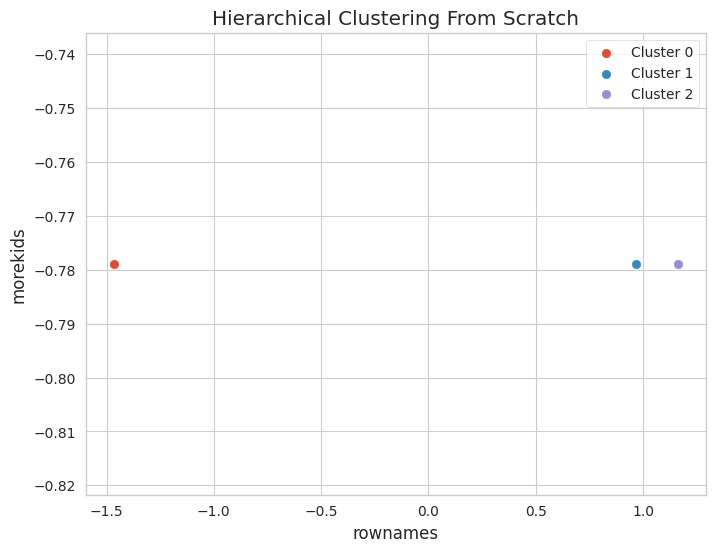

In [70]:
plt.figure(figsize=(8, 6))

for cluster_number in range(K):

    points = X_sample[
        labels == cluster_number
    ]

    plt.scatter(
        points[:, 0],
        points[:, 1],
        label=f"Cluster {cluster_number}"
    )

plt.xlabel(num_df.columns[0])
plt.ylabel(num_df.columns[1])

plt.title(
    "Hierarchical Clustering From Scratch"
)

plt.legend()

plt.show()

In [71]:
result = df.iloc[sample_indices].copy()

result["Hierarchical_Cluster"] = labels

result.to_csv(
    "Fertility2_Hierarchical_Result.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.
